In [1]:
import argparse
import collections
import csv
import gzip
import matplotlib.pyplot as plt
import numpy as np
import pandas

In [2]:
"""
Elements of the VCF to AHMM script.

Reading sample files.
"""


def read_sample_file(filename):
    pop_sample_map = collections.defaultdict(list)
    ordered_pops = []
    with open(filename) as file:
        for line in file:
            samp, pop = line.split()
            pop_sample_map[pop].append(samp)
            if pop not in ordered_pops and pop != "admixed":
                ordered_pops.append(pop)
    return ordered_pops, pop_sample_map


ordered_pops, pop_sample_map = read_sample_file("../../results/VCF_to_AHMM.samples")
print(ordered_pops)
for pop, samples in pop_sample_map.items():
    print(pop, samples[:5], samples[-5:])

['0', '1']
0 ['FR106N_1.fastq', 'FR109N_1.fastq', 'FR112N_1.fastq', 'FR113N_1.fastq', 'FR115N_1.fastq'] ['FR73N_1.fastq', 'FR89N_1.fastq', 'FR90N_1.fastq', 'FR91N_1.fastq', 'FR94N_1.fastq']
1 ['20260213ZI256', '20260213ZI268', '20260213ZI318N', '20260213ZI31N', '20260213ZI370N'] ['29Aug24-15-ZI357N', '29Aug24-16-ZI360N', '29Aug24-18-ZI251', '29Aug24-21-ZI394N', '29Aug24-22-ZI31N']
admixed ['DGRP-3-0001_S1', 'DGRP-3-0002_S2', 'DGRP-3-0003_S3', 'DGRP-3-0004_S4', 'DGRP-3-0005_S5'] ['DGRP-3-1268_S25', 'DGRP-3-1269_S26', 'DGRP-3-1270_S27', 'DGRP-3-1271_S28', 'DGRP-3-1272_S29']


In [3]:
"""
Recombination map vs. uniform recombination rate decision.
"""


def try_statement(rec):
    try:
        float(rec)
        use_uniform_r = True
    except:
        use_uniform_r = False
    return use_uniform_r


print(try_statement("1e-8"))
print(try_statement("path/to/map"))

True
False


In [76]:
"""
Recombination map loading.
"""

def load_rec_map(filename, chrom):
    df = pandas.read_csv(filename, sep="\\s+")
    # Subset to `chrom` and extract interval endpoints
    sub_df = df[df["Chrom"] == chrom]
    map_xs = [1]
    map_ys = [0]
    for _, row in sub_df.iterrows():
        start = row["Start"]
        stop = row["Stop"]
        # Convert to M/bp
        rate = row["cM/Mb"] * 1e-8
        map_span = (stop - start + 1) * rate
        map_y = map_ys[-1] + map_span
        map_xs.append(stop)
        map_ys.append(map_y)
    # Set up a function to interpolate site map coordinates
    rec_map = lambda x: np.interp(x, map_xs, map_ys)
    return rec_map


df = pandas.read_csv("../../results/recomb_r6.tsv", sep="\\s+")
rec_map = load_rec_map(filename, "X")

df_X = df[df["Chrom"] == "X"]
dists = []
for _, row in df_X.iterrows():
    start = row["Start"]
    stop = row["Stop"]
    length = stop - start + 1
    dist = (rec_map(stop) - rec_map(start)) / length * 1e8
    dists.append(dist)
df_X["c"] = dists
print(df_X[:30])

   Chrom    Start     Stop     cM/Mb         c
0      X        1   203004  0.010000  0.010000
1      X   203005   305967  0.010000  0.010000
2      X   305968   405967  0.010000  0.010000
3      X   405968   505967  0.010000  0.010000
4      X   505968   605967  0.010000  0.010000
5      X   605968   705967  0.010000  0.010000
6      X   705968   805967  0.010000  0.010000
7      X   805968   905967  0.010000  0.010000
8      X   905968  1005967  0.010000  0.010000
9      X  1005968  1105967  0.010000  0.010000
10     X  1105968  1205967  0.361671  0.361667
11     X  1205968  1305967  0.361671  0.361667
12     X  1305968  1405967  0.361671  0.361667
13     X  1405968  1505967  0.010000  0.010000
14     X  1505968  1605967  0.361671  0.361667
15     X  1605968  1705967  0.090418  0.090417
16     X  1705968  1805967  0.010000  0.010000
17     X  1805968  1905967  0.180835  0.180833
18     X  1905968  2005967  0.010000  0.010000
19     X  2005968  2105967  0.180835  0.180833
20     X  210

In [61]:

line0 = [
    "#CHROM",
    "POS",
    "ID",
    "REF",
    "ALT",
    "QUAL",
    "FILTER",
    "INFO",
    "FORMAT",
    "A0",
    "A1",
    "A2",
    "B0",
    "B1",
    "C0",
    "C1",
    "C2", 
    "C3"
]
line1 = [
    "X",
    "1000",
    ".",
    "A",
    "T",
    ".",
    ".",
    ".",
    "GT:AD",
    "1|1:0,30",
    "1|1:0,30",
    "1|0:15,15",
    "0/1:15,15",
    "0/0:30,0",
    "0/1:15,15",
    "1/1:0,30",
    "0/0:30,0",
    "0/1:15,15",
]
lines = [line0, line1]

ordered_pops = [0, 1]
pop_sample_map = {0: ["A0", "A1", "A2"], 1: ["B0", "B1"], "admixed": ["C0", "C1", "C2", "C3"]}

m = 0
min_samples = 1
min_diff = 0
g = 1

last_position = 0
last_map_coord = 0
current_chrom = "."

use_uniform_r = True
r = 1e-8

for line in lines:
    # Header information
    if line[0].startswith("##"):
        continue

    if line[0] == "#CHROM":
        header = line
        # Build a population-to-sample index mapping
        # These index the line, not the samples in the line. Hence
        # the index of the first sample column is 9.
        pop_idx_map = {
            pop: [header.index(s) for s in pop_sample_map[pop]]
            for pop in pop_sample_map}
        continue

    # Skip sites that are not biallelic SNPs
    if len(line[3]) != 1 or len(line[4]) != 1:
        continue

    if current_chrom != line[0]:
        current_chrom = line[0]
        last_position = 0
        last_map_coord = 0
        if not use_uniform_r:
            rec_map = lambda x: np.interp(
                x, rec_data[chrom]["xs"], rec_data[chrom]["ys"])

    # Skip if the last position is too close
    elif int(line[1]) - last_position < m:
        continue

    # Get population allele counts
    alts = collections.defaultdict(int)
    tots = collections.defaultdict(int)
    for pop in ordered_pops:
        for idx in pop_idx_map[pop]:
            # Assume genotype is the first three sample chars
            genotype = line[idx][:3]
            # Replace phased GT symbol
            if "|" in genotype:
                genotype = genotype.replace("|", "/")
            if genotype == "0/0":
                tots[pop] += 2
            elif genotype == "0/1" or genotype == "1/0":
                alts[pop] += 1
                tots[pop] += 2
            elif genotype == "1/1":
                alts[pop] += 2
                tots[pop] += 2
            # Use haploid genotype if needed
            elif genotype.startswith("0"):
                tots[pop] += 1
            elif genotype.startswith("1"):
                alts[pop] += 1
                tots[pop] += 1

    # Make sure there are enough sampled alleles
    skip = False
    freqs = []
    for pop, tot in tots.items():
        freqs.append(alts[pop]/tot)
        if tot < min_samples:
            skip = True
    if skip:
        continue

    # Skip if allele frequency difference is not great enough
    for i in range(0, len(freqs) - 1):
        for j in range(i + 1, len(freqs)):
            if abs(freqs[i] - freqs[j]) < min_diff:
                skip = True
    if skip:
        continue

    # Start printing site information
    print(line[0], line[1], end="\t", sep="\t")
    for pop in ordered_pops:
        tot = tots[pop]
        alt = alts[pop]
        ref = tot - alt
        print(ref, alt, end="\t", sep="\t")

    # Compute map distance to the last site
    if use_uniform_r:
        map_coord = int(line[1]) * r
    else:
        position = int(line[1])
        map_coord = rec_map(position)
    map_dist = map_coord - last_map_coord
    print(map_dist, end="")

    # Print counts for each admixed sample
    for idx in pop_idx_map["admixed"]:
        # Use genotype information
        if g == 1:
            # For diploids, GT should be the first three characters X/X
            genotype = line[idx][:3]
            # Replace phased GT symbol
            if "|" in genotype:
                genotype = genotype.replace("|", "/")
            if genotype == "0/0":
                print("\t", 2, "\t", 0, end="", sep="")
            elif genotype == "0/1":
                print("\t", 1, "\t", 1, end="", sep="")
            elif genotype == "1/1":
                print("\t", 0, "\t", 2, end="", sep="")
           # Haploids
            elif genotype.startswith("0"):
                print("\t", 1, "\t", 0, end="", sep="")
            elif genotype.startswith("1"):
                print("\t", 0, "\t", 1, end="", sep="")
            else:
                print("\t", 0, "\t", 0, end="", sep="")

        # Use read count information
        else:
            fields = line[idx].split(":")
            # Assume sample format is GT:AD:...
            if len(fields) > 1:
                ad = fields[1].split(",")
                print("\t", ad[0], "\t", ad[1], end="", sep="")
            else:
                print("\t", "0", "\t", "0", end="", sep="")

X	1000	1	5	3	1	1e-05	1	1	0	2	2	0	1	1

In [74]:
df = pandas.read_csv("../../results/AHMM_inputs/DGRP-3-0001_S1.tsv", sep="\t",
                    names=range(9))
c = np.array(df[df[0] == "X"][6])
np.cumsum(c)[-1]

np.float64(0.44077133648279615)

Text(0, 0.5, 'map (M)')

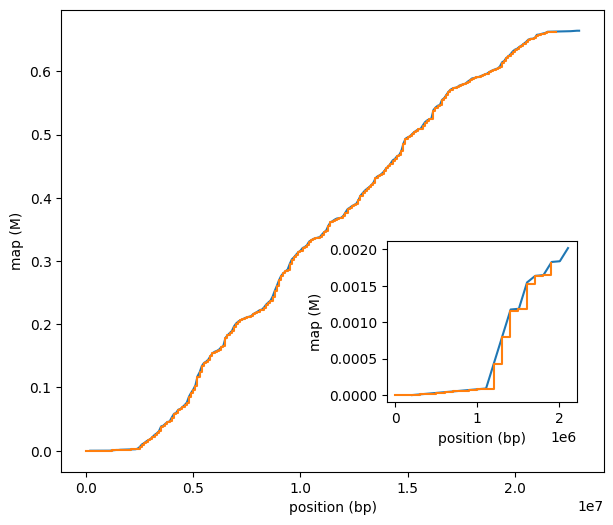

In [3]:
"""
Computing map distances from a recombination map.
AncestryHMM needs map distances in M between marker i-1 and marker i
in row i. The value in row 0 doesn't matter.
"""
# Pick some arbitrary 1-indexed sites. 
sites = np.arange(0, 22000000, 100000) + 1

df = pandas.read_csv("data/recomb_build6.tsv", sep="\\s+")
# Subset to one chromosome and extract arrays
df_X = df[df["Chrom"] == "X"]
starts = np.array(df_X["Start"])
stops = np.array(df_X["Stop"])
# Convert from cM/Mb to cM/bp
rates_M = np.array(df_X["cM/Mb"]) * 1e-8
# Calculate sites spanned by each interval
map_spans_bp = stops - starts + 1
map_spans_M = map_spans_bp * rates_M
map_M = np.cumsum(map_spans_M)
map_M = np.concatenate([[0], map_M])
map_bp = np.concatenate([[starts[0]], stops])
# Interpolate site map coordinates
site_M = np.interp(sites, map_bp, map_M)
site_M_diffs = np.concatenate([[0], site_M[1:] - site_M[:-1]])

fig, ax = plt.subplots(1, 1, figsize=(7, 6))
ax.plot(map_bp, map_M)
ax.set_xlabel("position (bp)")
ax.set_ylabel("map (M)")
ax.step(sites, np.cumsum(site_M_diffs), where="post")
inset = ax.inset_axes((0.6, 0.15, 0.35, 0.35))
inset.plot(map_bp[:20], map_M[:20])
inset.step(sites[:20], np.cumsum(site_M_diffs)[:20], where="post")
inset.set_xlabel("position (bp)")
inset.set_ylabel("map (M)")

In [59]:
# Type-counting example. Example interaction from Pool (2015):
# Locus                      AA    AE    EA   EE    FET p
# X 20,815,287–20,820,196    17    58    0    92    4e-7
# 3L 4,416,058–4,419,369




# Build 6 coordinates (from Flybase): X:20,815,287..20,820,196 --> X:20,944,260..20,949,169
start_X = 20_944_260
stop_X = 20_949_169

# 3L:4,416,058..4,419,369 -> 3L:4,416,058..4,419,369 (unchanged!)
start_3L = 4_416_058
stop_3L = 4_419_369

df = pandas.read_csv("../../results/ancestry/DGRP-2_subset_ancestry.tsv", sep="\\s+")
X_df = df[df["chrom"] == "X"]
X_loci_df = X_df[(X_df["position"] >= start_X) & (X_df["position"] <= stop_X)]

L3_df = df[df["chrom"] == "3L"]
L3_loci_df = L3_df[(L3_df["position"] >= start_3L) & (L3_df["position"] <= stop_3L)]

      chrom  position  DGRP-3-0001_S1  DGRP-3-0002_S2  DGRP-3-0003_S3  \
98760     X  20946115               1               0               1   
98761     X  20947140               1               0               1   
98762     X  20948224               1               0               1   

       DGRP-3-0004_S4  DGRP-3-0005_S5  DGRP-3-0006_S6  DGRP-3-0007_S7  \
98760               0               0               0               1   
98761               0               0               0               1   
98762               0               0               0               1   

       DGRP-3-0008_S8  ...  DGRP-3-0196_S36  DGRP-3-0197_S37  DGRP-3-0198_S38  \
98760               0  ...               -1                0                0   
98761               0  ...               -1                0                0   
98762               0  ...               -1                0                0   

       DGRP-3-0199_S39  DGRP-3-0200_S40  DGRP-3-0201_S41  DGRP-3-0202_S42  \
98760       

In [60]:
samples = list(df.columns[2:])
comparisons = []
type_counts = []
for i, X_row in X_loci_df.iterrows():
    for j, L3_row in L3_loci_df.iterrows():
        locus_X = f"{X_row['chrom']}-{X_row['position']}"
        locus_L3 = f"{L3_row['chrom']}-{L3_row['position']}"
        comparisons.append((locus_X, locus_L3))
        type_counts_ij = [0, 0, 0, 0]
        for idx, sample in enumerate(samples):
            anc_1 = X_row[samples[idx]]
            anc_2 = L3_row[samples[idx]]
            if anc_1 == 1 and anc_2 == 1: # AA
                type_counts_ij[0] += 1
            elif anc_1 == 1 and anc_2 == 0: # AE
                type_counts_ij[1] += 1
            elif anc_1 == 0 and anc_2 == 1: # EA
                type_counts_ij[2] += 1
            elif anc_1 == 0 and anc_2 == 0: # EE
                type_counts_ij[3] += 1
        type_counts.append(type_counts_ij)

for comp, counts in zip(comparisons, type_counts):
    print(comp, counts, sum(counts))

('X-20946115', '3L-4417055') [1, 35, 9, 127] 172
('X-20946115', '3L-4418115') [0, 36, 8, 127] 171
('X-20946115', '3L-4419320') [1, 35, 9, 127] 172
('X-20947140', '3L-4417055') [1, 36, 9, 129] 175
('X-20947140', '3L-4418115') [0, 36, 8, 129] 173
('X-20947140', '3L-4419320') [1, 36, 9, 129] 175
('X-20948224', '3L-4417055') [1, 37, 9, 128] 175
('X-20948224', '3L-4418115') [0, 38, 8, 128] 174
('X-20948224', '3L-4419320') [1, 37, 9, 128] 175
